In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import os

base_path = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset"

for root, dirs, files in os.walk(base_path):
    print("\nFOLDER:", root)

    for d in dirs:
        print("   [DIR] ", d)

    for f in files[:20]:
        print("   [FILE]", f)


FOLDER: /kaggle/input/datasets/akhilchibber/deforestation-detection-dataset
   [DIR]  2_CLOUDY_DATASET
   [DIR]  1_CLOUD_FREE_DATASET
   [DIR]  3_TRAINING_MASKS

FOLDER: /kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/2_CLOUDY_DATASET
   [DIR]  1_SENTINEL1
   [DIR]  2_SENTINEL2
   [FILE] Readme.txt

FOLDER: /kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/2_CLOUDY_DATASET/1_SENTINEL1
   [DIR]  IMAGE_16_GRID
   [DIR]  IMAGE_FULL

FOLDER: /kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/2_CLOUDY_DATASET/1_SENTINEL1/IMAGE_16_GRID
   [FILE] RASTER_15.tif
   [FILE] RASTER_8.tif
   [FILE] RASTER_6.tif
   [FILE] RASTER_11.tif
   [FILE] RASTER_4.tif
   [FILE] RASTER_14.tif
   [FILE] RASTER_13.tif
   [FILE] RASTER_10.tif
   [FILE] RASTER_0.tif
   [FILE] RASTER_3.tif
   [FILE] RASTER_1.tif
   [FILE] RASTER_5.tif
   [FILE] RASTER_7.tif
   [FILE] RASTER_12.tif
   [FILE] RASTER_2.tif
   [FILE] RASTER_9.tif

FOLDER: /kaggle/input/datasets/ak

In [2]:
import os
import numpy as np
import rasterio

mask_dir = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/"
    "3_TRAINING_MASKS/MASK_16_GRID"
)

mask_files = sorted([
    f for f in os.listdir(mask_dir)
    if f.endswith(".tif")
])

print("Number of masks:", len(mask_files))

for file in mask_files:
    path = os.path.join(mask_dir, file)

    with rasterio.open(path) as src:
        mask = src.read(1)

        values, counts = np.unique(mask, return_counts=True)

        print("\n", file)
        print("Shape:", mask.shape)
        print("Unique values:", values)

        for v, c in zip(values, counts):
            print(f"  {v}: {c} pixels ({100*c/mask.size:.2f}%)")

Number of masks: 16

 RASTER_0.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 256372 pixels (3.23%)
  2: 7673484 pixels (96.77%)

 RASTER_1.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 227899 pixels (2.87%)
  2: 7701957 pixels (97.13%)

 RASTER_10.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 4582569 pixels (57.79%)
  2: 3347287 pixels (42.21%)

 RASTER_11.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 3934698 pixels (49.62%)
  2: 3995158 pixels (50.38%)

 RASTER_12.tif
Shape: (2816, 2816)
Unique values: [0 1 2]
  0: 2 pixels (0.00%)
  1: 4211501 pixels (53.11%)
  2: 3718353 pixels (46.89%)

 RASTER_13.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 4488811 pixels (56.61%)
  2: 3441045 pixels (43.39%)

 RASTER_14.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 5373230 pixels (67.76%)
  2: 2556626 pixels (32.24%)

 RASTER_15.tif
Shape: (2816, 2816)
Unique values: [1 2]
  1: 3388588 pixels (42.73%)
  2: 4541268 pixels (57.27%)

 RASTER_2.tif
Shape: (2816, 2816)
Unique 

In [3]:
y = np.where(mask == 1, 1, 0)


In [4]:
import rasterio
import numpy as np

s1_path = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/"
    "1_CLOUD_FREE_DATASET/"
    "1_SENTINEL1/IMAGE_16_GRID/RASTER_0.tif"
)

with rasterio.open(s1_path) as src:
    print("Number of bands:", src.count)
    print("Image size:", src.width, "x", src.height)
    print("CRS:", src.crs)
    print("Data type:", src.dtypes)

    for band in range(1, src.count + 1):
        arr = src.read(band)

        print(f"\nBand {band}")
        print("Min:", np.nanmin(arr))
        print("Max:", np.nanmax(arr))
        print("Mean:", np.nanmean(arr))
        print("Std:", np.nanstd(arr))

Number of bands: 2
Image size: 2816 x 2816
CRS: EPSG:32722
Data type: ('float32', 'float32')

Band 1
Min: -1.9904351
Max: 14.438725
Mean: 0.10803937
Std: 0.5710361

Band 2
Min: -1.8647826
Max: 9.46959
Mean: 0.14595366
Std: 0.55668926


In [5]:
with rasterio.open(s1_path) as src:
    print("Dataset metadata:")
    print(src.tags())

    for band in range(1, src.count + 1):
        print(f"\nBand {band} metadata:")
        print(src.tags(band))

Dataset metadata:
{'TIFFTAG_SOFTWARE': 'IMAGINE TIFF Support\nCopyright 1991 - 1999 by ERDAS, Inc. All Rights Reserved\n@(#)$RCSfile: etif.c $ $Revision: 1.10.1.9.1.9.2.11 $ $Date: 2004/09/15 18:42:01EDT $', 'TIFFTAG_XRESOLUTION': '1', 'TIFFTAG_YRESOLUTION': '1', 'TIFFTAG_RESOLUTIONUNIT': '1 (unitless)', 'AREA_OR_POINT': 'Area'}

Band 1 metadata:
{'LAYER_TYPE': 'athematic', 'OVERVIEWS_ALGORITHM': 'ErdasBino3'}

Band 2 metadata:
{'LAYER_TYPE': 'athematic', 'OVERVIEWS_ALGORITHM': 'ErdasBino3'}


In [6]:
readme_s1 = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/"
    "1_CLOUD_FREE_DATASET/Readme.txt"
)

with open(readme_s1, "r", errors="ignore") as f:
    print(f.read())

Title of the dataset:
CLOUD FREE DATASET FOR PERFORMING SEMANTIC SEGMENTATION FOR DEFORESTATION MAPPING USING DEEP LEARNING BASED LATE FUSION ARCHITECTURE


Creators:
AKHIL CHHIBBER


Contributors:
1. RAIAN VARGAS MARETTE
2. MARIANA BELGIU
3. SUGANDH CHAUHAN


Description:
This folder includes a total of two sub folders titled (i) 1_SENTINEL1 and (ii) 2_SENTINEL2. 


Keywords:
SENTINEL1, SENTINEL2, CLOUD FREE


This dataset contains the following folders:
1. 1_SENTINEL1 
2. 2_SENTINEL2


Explanation of variables:
1. Firstly, the "1_SENTINEL1" folder includes the Sentinel-1 dataset dated 22nd July 2020. This dataset is further sub-divided into two seperate folders, (i) IMAGE_FULL which includes the complete raster of the study area and (ii) IMAGE_16_GRID which includes 16 patches which covers the study area.
2. Secondly, the "2_SENTINEL2" folder includes the Sentinel-2 dataset dated 27th July 2020. This dataset is further sub-divided into two seperate folders, (i) IMAGE_FULL which inclu

In [7]:
import rasterio

s1_path = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/"
    "1_CLOUD_FREE_DATASET/"
    "1_SENTINEL1/IMAGE_16_GRID/RASTER_0.tif"
)

with rasterio.open(s1_path) as src:

    print("Band descriptions:")
    print(src.descriptions)

    print("\nBand color interpretations:")
    print(src.colorinterp)

    print("\nSubdatasets:")
    print(src.subdatasets)

Band descriptions:
('Layer_1', 'Layer_2')

Band color interpretations:
(<ColorInterp.red: 3>, <ColorInterp.green: 4>)

Subdatasets:
[]


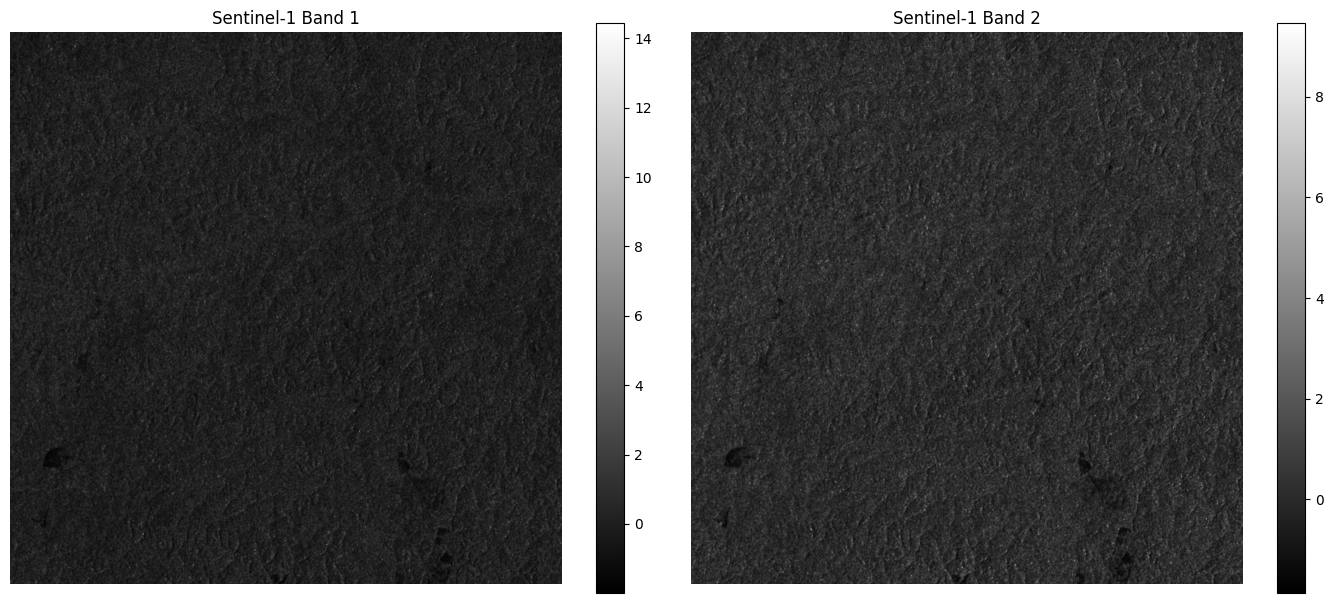

In [8]:
import rasterio
import matplotlib.pyplot as plt

with rasterio.open(s1_path) as src:
    band1 = src.read(1)
    band2 = src.read(2)

plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1)
plt.imshow(band1, cmap="gray")
plt.title("Sentinel-1 Band 1")
plt.colorbar()
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(band2, cmap="gray")
plt.title("Sentinel-1 Band 2")
plt.colorbar()
plt.axis("off")

plt.tight_layout()
plt.show()

SAR patch shape: (2, 256, 256)
Mask patch shape: (256, 256)

SAR Band 1 range: -1.4335749 to 6.045302
SAR Band 2 range: -1.3369179 to 7.0602303

Mask values: (array([2], dtype=uint8), array([65536]))


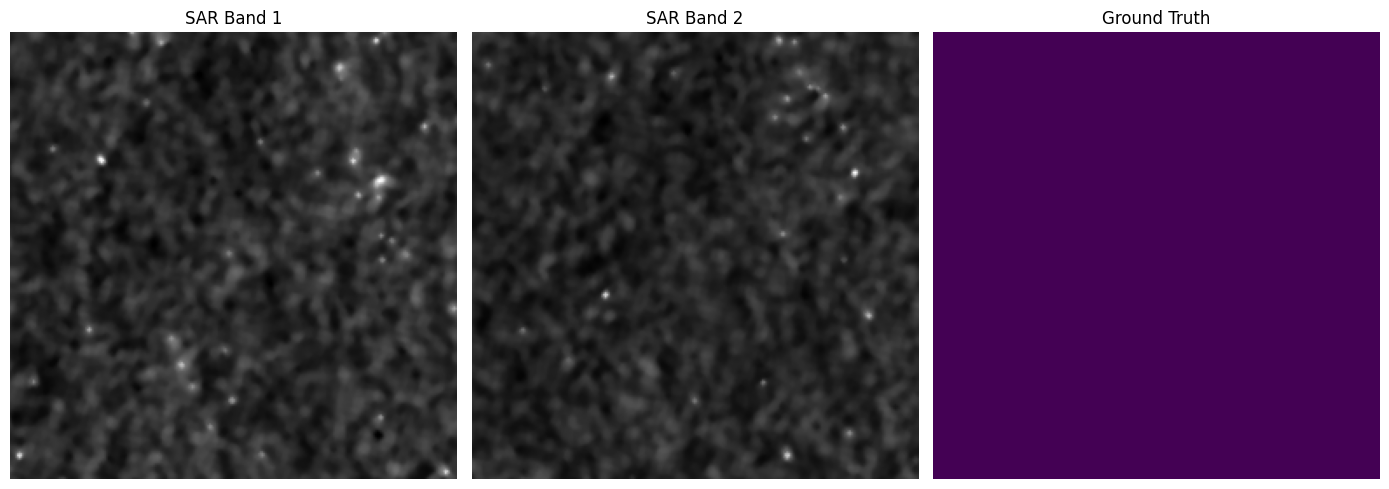

In [9]:
import rasterio
import numpy as np
import matplotlib.pyplot as plt

# RASTER_0
s1_path = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/"
    "1_CLOUD_FREE_DATASET/1_SENTINEL1/"
    "IMAGE_16_GRID/RASTER_0.tif"
)

mask_path = (
    "/kaggle/input/datasets/akhilchibber/"
    "deforestation-detection-dataset/3_TRAINING_MASKS/"
    "MASK_16_GRID/RASTER_0.tif"
)

with rasterio.open(s1_path) as src:
    sar = src.read()   # shape: bands, height, width

with rasterio.open(mask_path) as src:
    mask = src.read(1)

# Take the first 256 x 256 patch
sar_patch = sar[:, 0:256, 0:256]
mask_patch = mask[0:256, 0:256]

print("SAR patch shape:", sar_patch.shape)
print("Mask patch shape:", mask_patch.shape)

print("\nSAR Band 1 range:",
      sar_patch[0].min(), "to", sar_patch[0].max())

print("SAR Band 2 range:",
      sar_patch[1].min(), "to", sar_patch[1].max())

print("\nMask values:", np.unique(mask_patch, return_counts=True))

# Display
plt.figure(figsize=(14, 5))

plt.subplot(1, 3, 1)
plt.imshow(sar_patch[0], cmap="gray")
plt.title("SAR Band 1")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(sar_patch[1], cmap="gray")
plt.title("SAR Band 2")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(mask_patch)
plt.title("Ground Truth")
plt.axis("off")

plt.tight_layout()
plt.show()

In [10]:
import os
import numpy as np
import rasterio

SAR_DIR = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/1_CLOUD_FREE_DATASET/1_SENTINEL1/IMAGE_16_GRID"
MASK_DIR = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/3_TRAINING_MASKS/MASK_16_GRID"

TRAIN_TILES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15]

PATCH_SIZE = 256

total_patches = 0
only_deforestation = 0
only_non_deforestation = 0
mixed = 0

for tile in TRAIN_TILES:

    mask_path = os.path.join(
        MASK_DIR, f"RASTER_{tile}.tif"
    )

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    h, w = mask.shape

    for r in range(0, h, PATCH_SIZE):
        for c in range(0, w, PATCH_SIZE):

            patch = mask[
                r:r + PATCH_SIZE,
                c:c + PATCH_SIZE
            ]

            if patch.shape != (PATCH_SIZE, PATCH_SIZE):
                continue

            valid = patch[(patch == 1) | (patch == 2)]

            if len(valid) == 0:
                continue

            total_patches += 1

            unique = np.unique(valid)

            if np.array_equal(unique, [1]):
                only_deforestation += 1

            elif np.array_equal(unique, [2]):
                only_non_deforestation += 1

            else:
                mixed += 1

print("Total valid patches:", total_patches)
print("Only deforestation:", only_deforestation)
print("Only non-deforestation:", only_non_deforestation)
print("Mixed:", mixed)

Total valid patches: 1694
Only deforestation: 16
Only non-deforestation: 328
Mixed: 1350


In [11]:
import os
import numpy as np
import rasterio

MASK_DIR = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/3_TRAINING_MASKS/MASK_16_GRID"

TRAIN_TILES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15]

deforestation_pixels = 0
non_deforestation_pixels = 0
nodata_pixels = 0

for tile in TRAIN_TILES:

    path = os.path.join(
        MASK_DIR,
        f"RASTER_{tile}.tif"
    )

    with rasterio.open(path) as src:
        mask = src.read(1)

    deforestation_pixels += np.sum(mask == 1)
    non_deforestation_pixels += np.sum(mask == 2)
    nodata_pixels += np.sum(mask == 0)

total = (
    deforestation_pixels +
    non_deforestation_pixels
)

print("Deforestation pixels:", deforestation_pixels)
print("Non-deforestation pixels:", non_deforestation_pixels)
print("NoData pixels:", nodata_pixels)

print("\nTotal valid pixels:", total)

print(
    "Deforestation %:",
    100 * deforestation_pixels / total
)

print(
    "Non-deforestation %:",
    100 * non_deforestation_pixels / total
)

Deforestation pixels: 39665760
Non-deforestation pixels: 71352223
NoData pixels: 1

Total valid pixels: 111017983
Deforestation %: 35.72913047789744
Non-deforestation %: 64.27086952210256


In [12]:
import os
import numpy as np
import rasterio

SAR_DIR = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/1_CLOUD_FREE_DATASET/1_SENTINEL1/IMAGE_16_GRID"
MASK_DIR = "/kaggle/input/datasets/akhilchibber/deforestation-detection-dataset/3_TRAINING_MASKS/MASK_16_GRID"

TRAIN_TILES = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 13, 15]

SAMPLES_PER_CLASS_PER_TILE = 5000

rng = np.random.default_rng(42)

X_train = []
y_train = []

for tile in TRAIN_TILES:

    sar_path = os.path.join(
        SAR_DIR,
        f"RASTER_{tile}.tif"
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"RASTER_{tile}.tif"
    )

    with rasterio.open(sar_path) as src:
        sar = src.read().astype(np.float32)

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    band1 = sar[0].ravel()
    band2 = sar[1].ravel()
    labels = mask.ravel()

    valid = (labels == 1) | (labels == 2)

    band1 = band1[valid]
    band2 = band2[valid]
    labels = labels[valid]


    labels = np.where(labels == 1, 1, 0)

    def_idx = np.where(labels == 1)[0]
    nondef_idx = np.where(labels == 0)[0]

    n = min(
        SAMPLES_PER_CLASS_PER_TILE,
        len(def_idx),
        len(nondef_idx)
    )

    def_idx = rng.choice(def_idx, n, replace=False)
    nondef_idx = rng.choice(nondef_idx, n, replace=False)

    selected = np.concatenate([def_idx, nondef_idx])

    tile_X = np.column_stack([
        band1[selected],
        band2[selected]
    ])

    tile_y = labels[selected]

    X_train.append(tile_X)
    y_train.append(tile_y)
X_train = np.concatenate(X_train)
y_train = np.concatenate(y_train)
idx = rng.permutation(len(y_train))
X_train = X_train[idx]
y_train = y_train[idx]

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)
print("\nClass counts:")
print("Non-deforestation:", np.sum(y_train == 0))
print("Deforestation:", np.sum(y_train == 1))

X_train shape: (140000, 2)
y_train shape: (140000,)

Class counts:
Non-deforestation: 70000
Deforestation: 70000


In [13]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

rf = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf.fit(X_train, y_train)

rf_train_pred = rf.predict(X_train)

print("Random Forest Training Results")
print("--------------------------------")

print("Accuracy :", accuracy_score(y_train, rf_train_pred))
print("Precision:", precision_score(y_train, rf_train_pred, zero_division=0))
print("Recall   :", recall_score(y_train, rf_train_pred, zero_division=0))
print("F1 Score :", f1_score(y_train, rf_train_pred, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_train, rf_train_pred))

Random Forest Training Results
--------------------------------
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1 Score : 1.0

Confusion Matrix:
[[70000     0]
 [    0 70000]]


In [14]:
import os
import numpy as np
import rasterio

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

TEST_TILES = [12, 14]

X_test = []
y_test = []

for tile in TEST_TILES:

    sar_path = os.path.join(
        SAR_DIR,
        f"RASTER_{tile}.tif"
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"RASTER_{tile}.tif"
    )

    print(f"Loading RASTER_{tile}...")

    with rasterio.open(sar_path) as src:
        sar = src.read().astype(np.float32)

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    band1 = sar[0].ravel()
    band2 = sar[1].ravel()
    labels = mask.ravel()

    # Keep only valid ground-truth pixels
    valid = (labels == 1) | (labels == 2)

    band1 = band1[valid]
    band2 = band2[valid]
    labels = labels[valid]
    labels = np.where(labels == 1, 1, 0)

    tile_X = np.column_stack([
        band1,
        band2
    ])

    X_test.append(tile_X)
    y_test.append(labels)

X_test = np.concatenate(X_test)
y_test = np.concatenate(y_test)

print("\nTest data:")
print("X_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTest class distribution:")
print("Non-deforestation:", np.sum(y_test == 0))
print("Deforestation:", np.sum(y_test == 1))


rf_test_pred = rf.predict(X_test)
print("\n==========================================")
print("RANDOM FOREST - UNSEEN TEST TILES")
print("==========================================")

print("\nAccuracy :",
      accuracy_score(y_test, rf_test_pred))

print("Precision:",
      precision_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("Recall   :",
      recall_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("F1 Score :",
      f1_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        rf_test_pred
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=[
            "Non-Deforestation",
            "Deforestation"
        ],
        zero_division=0
    )
)

Loading RASTER_12...
Loading RASTER_14...

Test data:
X_test shape: (15859710, 2)
y_test shape: (15859710,)

Test class distribution:
Non-deforestation: 6274979
Deforestation: 9584731

RANDOM FOREST - UNSEEN TEST TILES

Accuracy : 0.7351753594485649
Precision: 0.7926170386314839
Recall   : 0.7608770658247999
F1 Score : 0.7764228070730174

Confusion Matrix:
[[4366866 1908113]
 [2291929 7292802]]

Classification Report:
                   precision    recall  f1-score   support

Non-Deforestation       0.66      0.70      0.68   6274979
    Deforestation       0.79      0.76      0.78   9584731

         accuracy                           0.74  15859710
        macro avg       0.72      0.73      0.73  15859710
     weighted avg       0.74      0.74      0.74  15859710



In [20]:
rf_test_pred = rf.predict(X_test)

print("Random Forest - Unseen Test Tiles")
print("----------------------------------")

print("Accuracy :",
      accuracy_score(y_test, rf_test_pred))

print("Precision:",
      precision_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("Recall   :",
      recall_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("F1 Score :",
      f1_score(
          y_test,
          rf_test_pred,
          zero_division=0
      ))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, rf_test_pred))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        rf_test_pred,
        target_names=[
            "Non-Deforestation",
            "Deforestation"
        ],
        zero_division=0
    )
)

Random Forest - Unseen Test Tiles
----------------------------------
Accuracy : 0.7351753594485649
Precision: 0.7926170386314839
Recall   : 0.7608770658247999
F1 Score : 0.7764228070730174

Confusion Matrix:
[[4366866 1908113]
 [2291929 7292802]]

Classification Report:
                   precision    recall  f1-score   support

Non-Deforestation       0.66      0.70      0.68   6274979
    Deforestation       0.79      0.76      0.78   9584731

         accuracy                           0.74  15859710
        macro avg       0.72      0.73      0.73  15859710
     weighted avg       0.74      0.74      0.74  15859710



In [15]:
import os
import numpy as np
import rasterio

def dry_coefficient(band):
    """
    Mean of values below the first quartile.
    This follows the dry-coefficient idea described
    by Yordanov & Brovelli for reducing SAR speckle.
    """
    q1 = np.percentile(band, 25)
    return np.mean(band[band < q1])


for tile in [0, 12]:
    
    sar_path = os.path.join(
        SAR_DIR,
        f"RASTER_{tile}.tif"
    )

    with rasterio.open(sar_path) as src:
        sar = src.read().astype(np.float32)

    band1 = sar[0]
    band2 = sar[1]

    dc_band1 = dry_coefficient(band1)
    dc_band2 = dry_coefficient(band2)

    print(f"RASTER_{tile}")
    print("Band 1 Q1:", np.percentile(band1, 25))
    print("Band 1 dry coefficient:", dc_band1)
    print("Band 2 Q1:", np.percentile(band2, 25))
    print("Band 2 dry coefficient:", dc_band2)
    print()

RASTER_0
Band 1 Q1: -0.27592382
Band 1 dry coefficient: -0.5419151
Band 2 Q1: -0.22481866
Band 2 dry coefficient: -0.48132753

RASTER_12
Band 1 Q1: -0.86112845
Band 1 dry coefficient: -1.1497647
Band 2 Q1: -0.8636888
Band 2 dry coefficient: -1.124077



In [16]:
import os
import numpy as np
import rasterio
from scipy.ndimage import uniform_filter

# Use RASTER_0 as a test example first
tile = 0

sar_path = os.path.join(
    SAR_DIR,
    f"RASTER_{tile}.tif"
)

with rasterio.open(sar_path) as src:
    sar = src.read().astype(np.float32)

band1 = sar[0]
band2 = sar[1]

# 7x7 local neighborhood, following the spatial-window idea
# used in the published SAR/RF literature
window = 7

# Local mean
mean_band1 = uniform_filter(band1, size=window)
mean_band2 = uniform_filter(band2, size=window)

# Local squared mean
mean_sq_band1 = uniform_filter(band1 ** 2, size=window)
mean_sq_band2 = uniform_filter(band2 ** 2, size=window)

# Local variance
var_band1 = np.maximum(
    mean_sq_band1 - mean_band1 ** 2,
    0
)

var_band2 = np.maximum(
    mean_sq_band2 - mean_band2 ** 2,
    0
)

std_band1 = np.sqrt(var_band1)
std_band2 = np.sqrt(var_band2)

difference = band1 - band2

ratio = band1 / (band2 + 1e-6)

features = np.stack(
    [
        band1,
        band2,
        difference,
        ratio,
        mean_band1,
        mean_band2,
        std_band1,
        std_band2
    ],
    axis=2
)

print("Feature array shape:", features.shape)
print("Number of features:", features.shape[2])

feature_names = [
    "Band_1",
    "Band_2",
    "Band_1_minus_Band_2",
    "Band_1_div_Band_2",
    "Local_Mean_Band_1",
    "Local_Mean_Band_2",
    "Local_STD_Band_1",
    "Local_STD_Band_2"
]

print("\nFeatures:")
for i, name in enumerate(feature_names):
    print(i + 1, name)

print("\nFeature means:")
for i, name in enumerate(feature_names):
    print(name, np.nanmean(features[:, :, i]))

Feature array shape: (2816, 2816, 8)
Number of features: 8

Features:
1 Band_1
2 Band_2
3 Band_1_minus_Band_2
4 Band_1_div_Band_2
5 Local_Mean_Band_1
6 Local_Mean_Band_2
7 Local_STD_Band_1
8 Local_STD_Band_2

Feature means:
Band_1 0.10803937
Band_2 0.14595366
Band_1_minus_Band_2 -0.037914302
Band_1_div_Band_2 0.4544325
Local_Mean_Band_1 0.10803936
Local_Mean_Band_2 0.14595374
Local_STD_Band_1 0.30064
Local_STD_Band_2 0.29001573


In [18]:
import os
import numpy as np
import rasterio
from scipy.ndimage import uniform_filter
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

WINDOW = 7
SAMPLES_PER_CLASS = 5000
rng = np.random.default_rng(42)

def create_features(sar):

    band1 = sar[0]
    band2 = sar[1]
    mean1 = uniform_filter(band1, size=WINDOW)
    mean2 = uniform_filter(band2, size=WINDOW)

    mean_sq1 = uniform_filter(band1 ** 2, size=WINDOW)
    mean_sq2 = uniform_filter(band2 ** 2, size=WINDOW)

    std1 = np.sqrt(
        np.maximum(mean_sq1 - mean1 ** 2, 0)
    )

    std2 = np.sqrt(
        np.maximum(mean_sq2 - mean2 ** 2, 0)
    )

    difference = band1 - band2
    ratio = band1 / (band2 + 1e-6)

    return np.stack(
        [
            band1,
            band2,
            difference,
            ratio,
            mean1,
            mean2,
            std1,
            std2
        ],
        axis=2
    )

def prepare_training_data(tile_ids):

    X_list = []
    y_list = []

    for tile in tile_ids:

        print("Processing training tile:", tile)

        sar_path = os.path.join(
            SAR_DIR,
            f"RASTER_{tile}.tif"
        )

        mask_path = os.path.join(
            MASK_DIR,
            f"RASTER_{tile}.tif"
        )

        with rasterio.open(sar_path) as src:
            sar = src.read().astype(np.float32)

        with rasterio.open(mask_path) as src:
            mask = src.read(1)

        features = create_features(sar)

        valid = (mask == 1) | (mask == 2)

        X = features[valid]
        y = np.where(mask[valid] == 1, 1, 0)

        def_idx = np.where(y == 1)[0]
        nondef_idx = np.where(y == 0)[0]

        n = min(
            SAMPLES_PER_CLASS,
            len(def_idx),
            len(nondef_idx)
        )

        def_idx = rng.choice(
            def_idx,
            n,
            replace=False
        )

        nondef_idx = rng.choice(
            nondef_idx,
            n,
            replace=False
        )

        selected = np.concatenate([
            def_idx,
            nondef_idx
        ])

        X_list.append(X[selected])
        y_list.append(y[selected])

    X = np.concatenate(X_list)
    y = np.concatenate(y_list)

    shuffle = rng.permutation(len(y))

    return X[shuffle], y[shuffle]


X_train_8, y_train_8 = prepare_training_data(
    TRAIN_TILES
)

print("\nTraining shape:", X_train_8.shape)
print("Training labels:", y_train_8.shape)
print("Non-deforestation:", np.sum(y_train_8 == 0))
print("Deforestation:", np.sum(y_train_8 == 1))


rf_8 = RandomForestClassifier(
    n_estimators=200,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

print("\nTraining Random Forest...")

rf_8.fit(
    X_train_8,
    y_train_8
)

X_test_8_list = []
y_test_8_list = []

for tile in TEST_TILES:

    print("Processing test tile:", tile)

    sar_path = os.path.join(
        SAR_DIR,
        f"RASTER_{tile}.tif"
    )

    mask_path = os.path.join(
        MASK_DIR,
        f"RASTER_{tile}.tif"
    )

    with rasterio.open(sar_path) as src:
        sar = src.read().astype(np.float32)

    with rasterio.open(mask_path) as src:
        mask = src.read(1)

    features = create_features(sar)

    valid = (mask == 1) | (mask == 2)

    X_test_8_list.append(features[valid])
    y_test_8_list.append(
        np.where(mask[valid] == 1, 1, 0)
    )

X_test_8 = np.concatenate(X_test_8_list)
y_test_8 = np.concatenate(y_test_8_list)

pred_8 = rf_8.predict(X_test_8)


accuracy_8 = accuracy_score(
    y_test_8,
    pred_8
)

precision_8 = precision_score(
    y_test_8,
    pred_8,
    zero_division=0
)

recall_8 = recall_score(
    y_test_8,
    pred_8,
    zero_division=0
)

f1_8 = f1_score(
    y_test_8,
    pred_8,
    zero_division=0
)

print("RF WITH 8 SAR FEATURES")
print("Accuracy :", accuracy_8)
print("Precision:", precision_8)
print("Recall   :", recall_8)
print("F1 Score :", f1_8)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_8,
        pred_8
    )
)

print("BASELINE vs FEATURE-BASED RF")
print(
    f"Accuracy: "
    f"2-feature = 0.7352 | "
    f"8-feature = {accuracy_8:.4f}"
)

print(
    f"F1 score: "
    f"2-feature = 0.7764 | "
    f"8-feature = {f1_8:.4f}"
)

Processing training tile: 0
Processing training tile: 1
Processing training tile: 2
Processing training tile: 3
Processing training tile: 4
Processing training tile: 5
Processing training tile: 6
Processing training tile: 7
Processing training tile: 8
Processing training tile: 9
Processing training tile: 10
Processing training tile: 11
Processing training tile: 13
Processing training tile: 15

Training shape: (140000, 8)
Training labels: (140000,)
Non-deforestation: 70000
Deforestation: 70000

Training Random Forest...
Processing test tile: 12
Processing test tile: 14
RF WITH 8 SAR FEATURES
Accuracy : 0.8070369508648014
Precision: 0.8422218405998991
Recall   : 0.8376237163046099
F1 Score : 0.839916485389494

Confusion Matrix:
[[4770974 1504005]
 [1556333 8028398]]
BASELINE vs FEATURE-BASED RF
Accuracy: 2-feature = 0.7352 | 8-feature = 0.8070
F1 score: 2-feature = 0.7764 | 8-feature = 0.8399


In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

svm_8 = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    ))
])

print("Training SVM...")

svm_8.fit(X_train_8, y_train_8)

print("SVM training completed.")

svm_pred_8 = svm_8.predict(X_test_8)


svm_accuracy = accuracy_score(
    y_test_8,
    svm_pred_8
)

svm_precision = precision_score(
    y_test_8,
    svm_pred_8,
    zero_division=0
)

svm_recall = recall_score(
    y_test_8,
    svm_pred_8,
    zero_division=0
)

svm_f1 = f1_score(
    y_test_8,
    svm_pred_8,
    zero_division=0
)

print("SVM- 8 SAR FEATURES")

print("Accuracy :", svm_accuracy)
print("Precision:", svm_precision)
print("Recall   :", svm_recall)
print("F1 Score :", svm_f1)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test_8,
        svm_pred_8
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test_8,
        svm_pred_8,
        target_names=[
            "Non-Deforestation",
            "Deforestation"
        ],
        zero_division=0
    )
)

print("\n======================================")
print("RF vs SVM")

print(
    f"{'Metric':<12}"
    f"{'RF':<15}"
    f"{'SVM':<15}"
)

print("-" * 42)

print(
    f"{'Accuracy':<12}"
    f"{accuracy_8:<15.4f}"
    f"{svm_accuracy:<15.4f}"
)

print(
    f"{'Precision':<12}"
    f"{precision_8:<15.4f}"
    f"{svm_precision:<15.4f}"
)

print(
    f"{'Recall':<12}"
    f"{recall_8:<15.4f}"
    f"{svm_recall:<15.4f}"
)

print(
    f"{'F1':<12}"
    f"{f1_8:<15.4f}"
    f"{svm_f1:<15.4f}"
)